# support 16개로 하는 보정: 공통 보정과 약물별 보정을 따로 보기

새 세포주에서 약물 16개만 실험했다고 하자. 다른 약물의 RNA 변화(Δ)를 예측할 때 이 16개가 **두 가지 다른 일**을 한다.

1. **공통 보정** — "이 세포주는 전반적으로 이만큼 다르다"는 벡터 하나. 모든 query 약물에 똑같이 더한다.
2. **약물별 보정** — query 약물과 닮은 support 약물의 잔차를 더 많이 빌려 오는 것. 약물마다 다르다.

이 노트북은 두 숫자를 **따로** 보여 준다.

- 여기서 "새 세포주"는 학습에 쓰지 않은 source 세포주(확인 family)다. HCC 자료는 열지 않는다.
- 아무것도 학습하지 않는다. 서버의 source 저장소가 필요하다(`experiments/replicate_calibrated_r8/env.sh`를 읽은 환경).

용어: **Δ** = 같은 plate 대조군 평균 대비 처리 후 978개 유전자의 변화. **f0** = 다른 세포주(family)들에서 같은 약물이 보인 Δ의 평균. **ΔRMSE** = 예측 Δ와 실제 Δ의 차이(낮을수록 좋음).

In [1]:
import os, sys, json
import numpy as np, pandas as pd, torch
import matplotlib
import matplotlib.pyplot as plt
ROOT = os.environ.get("R8_ROOT", os.getcwd())
os.chdir(ROOT); sys.path.insert(0, ROOT)
pd.set_option("display.width", 200); pd.set_option("display.float_format", lambda v: f"{v:.4f}")
BLUE, ORANGE, AQUA, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#8a8983"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "axes.axisbelow": True,
                     "grid.color": "#e4e3df", "grid.linewidth": 0.6, "axes.edgecolor": "#8a8983", "font.size": 10, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb"})
from src.replicate_calibrated_r8.common import proc
from src.replicate_calibrated_r8.data import Store, Features
from src.replicate_calibrated_r8.arms import Context
from src.replicate_calibrated_r8 import methods as M
from src.replicate_calibrated_r8.suite import load_learned
st = Store("cpu")
ctx = Context(Features.load(proc("feature_basis.npz"), "cpu"), st.FP)
CELL, SEED, K = "HCC515", 1, 16
ci = list(st.cell_name).index(CELL)
assert st.cell_role[ci] == "val"                       # a confirmation-family cell line, never used for training or selection
ep = st.eval_episode(ci, SEED)
inp = ep.inputs(K)                                      # everything a method may see: no query label inside
names = st.groups.drug_group.to_numpy()
print("virtual target:", CELL, "| support drugs K =", K, "| query drugs:", len(ep.g_q))
print("first support drugs:", ", ".join(names[ep.g_s[:4]]), "...")

virtual target: HCC515 | support drugs K = 16 | query drugs: 472
first support drugs: G:BRD-K18316707, G:BRD-K20714604, G:BRD-A19374631, G:BRD-A82307304 ...


## 1. support 16개에서 읽는 것: 잔차와 그 평균

support 약물마다 `실제 Δ − f*`를 계산한다(f*는 f0를 조금 줄인 것). 16개 잔차의 평균이 **공통 보정**의 재료다.

In [2]:
anc = ctx.anchor(inp, "iid")
rms = lambda x: float(torch.sqrt((x ** 2).mean()))
print(f"support residual size (RMS over 16 drugs x 978 genes): {rms(anc['E']):.4f}")
print(f"mean residual  = common part                         : {rms(anc['ebar']):.4f}")
print(f"what is left after removing the mean (per-drug part)  : {rms(anc['R']):.4f}")
print(f"shrink factor applied to the common part              : {anc['shrink']:.3f}   (K_eff = {anc['keff']:.1f})")
print(f"common correction actually added to every query drug  : {rms(anc['b']):.4f}")

support residual size (RMS over 16 drugs x 978 genes): 0.4915
mean residual  = common part                         : 0.1309
what is left after removing the mean (per-drug part)  : 0.4737
shrink factor applied to the common part              : 0.500   (K_eff = 16.0)
common correction actually added to every query drug  : 0.0654


## 2. 예측을 한 단계씩 쌓기

같은 query 약물들에 대해, 조각을 하나씩 더하면서 ΔRMSE가 어떻게 변하는지 본다.

In [3]:
rmse = lambda p: float(torch.sqrt(((p - ep.y_q) ** 2).mean(1)).mean())      # ep.y_q is used for scoring only
entry = json.load(open(ctx_path := "manifests/replicate_calibrated_r8/model_selection.json"))["final"]["B00"]["42"]
arm, model = load_learned(entry, "cpu")
with torch.no_grad():
    c0 = ctx.c0(inp, "iid")
    c1 = ctx.c1(inp, "iid")
    b00 = ctx.adapter(model, "B00", inp)
steps = [("no change (0)", torch.zeros_like(ep.y_q)), ("f0: same-drug mean of other cell lines", M.same_drug_mean(inp)), ("f*: shrunk f0", anc["fq"]),
         ("C0 = f* + common correction", c0), ("C1 = C0 + per-drug correction (no training)", c1), ("B00 = C0 + per-drug correction (trained)", b00)]
tab = pd.DataFrame([dict(step=n, delta_rmse=rmse(p)) for n, p in steps])
tab["change_vs_previous"] = tab.delta_rmse.diff()
print(tab.to_string(index=False))

                                       step  delta_rmse  change_vs_previous
                              no change (0)      0.4913                 NaN
     f0: same-drug mean of other cell lines      0.4791             -0.0123
                              f*: shrunk f0      0.4679             -0.0111
                C0 = f* + common correction      0.4691              0.0012
C1 = C0 + per-drug correction (no training)      0.4688             -0.0003
   B00 = C0 + per-drug correction (trained)      0.4681             -0.0008


## 3. 두 보정의 크기를 따로

- **공통 보정**이 줄인 오차 = (f*) − (C0)
- **약물별 보정**이 추가로 줄인 오차 = (C0) − (C1 또는 B00)

약물별 보정 벡터 자체의 크기도 함께 본다. 크기가 작으면 예측을 거의 바꾸지 않은 것이다.

common correction  : error reduced by -0.0012   (size of the added vector 0.0654)
per-drug, untrained (C1)  : error reduced by +0.0003   (size of the added vectors 0.0711)
per-drug, trained (B00)   : error reduced by +0.0011   (size of the added vectors 0.0762)


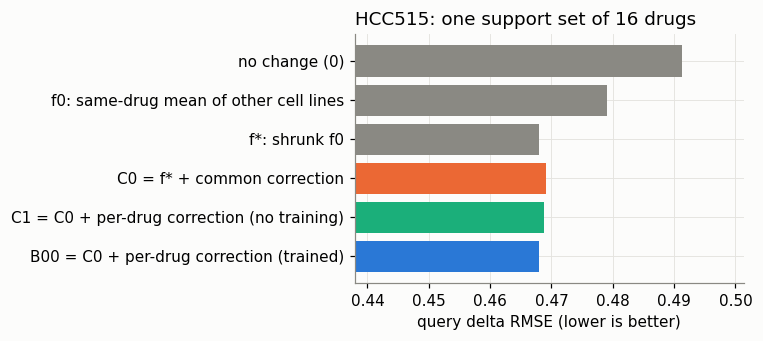

In [4]:
common_gain = rmse(anc["fq"]) - rmse(c0)
print(f"common correction  : error reduced by {common_gain:+.4f}   (size of the added vector {rms(anc['b']):.4f})")
for name, p in (("per-drug, untrained (C1)", c1), ("per-drug, trained (B00)", b00)):
    print(f"{name:26s}: error reduced by {rmse(c0) - rmse(p):+.4f}   (size of the added vectors {rms(p - c0):.4f})")
fig, ax = plt.subplots(figsize=(7.0, 3.2))
ax.barh([s[0] for s in steps][::-1], tab.delta_rmse[::-1], color=[GREY, GREY, GREY, ORANGE, AQUA, BLUE][::-1])
ax.set_xlim(tab.delta_rmse.min() - 0.03, tab.delta_rmse.max() + 0.01); ax.set_xlabel("query delta RMSE (lower is better)")
ax.set_title(f"{CELL}: one support set of {K} drugs", loc="left"); plt.tight_layout(); plt.show()

## 4. support 측정이 서로 독립이 아닐 때

같은 plate에서 잰 support들은 대조군을 함께 쓰므로 오차를 일부 공유한다. 관측 공분산 Ω를 쓰면 공통 보정의 가중치와 유효 표본 수(K_eff)가 달라진다.

In [5]:
anc_cov = ctx.anchor(inp, "cov")
print("support plates:", len(set(p for s in ep.plates_s[:K] for p in s.split("|"))), "distinct detection plates among", K, "support drugs")
print(f"iid: K_eff = {anc['keff']:.1f}, weights all {1 / K:.4f}")
print(f"cov: K_eff = {anc_cov['keff']:.1f}, weights from {float(anc_cov['w'].min()):.4f} to {float(anc_cov['w'].max()):.4f}")
with torch.no_grad():
    print(f"C0 iid {rmse(c0):.4f} | C0 cov {rmse(ctx.c0(inp, 'cov')):.4f} | C1 iid {rmse(c1):.4f} | C1 cov {rmse(ctx.c1(inp, 'cov')):.4f}")

support plates: 23 distinct detection plates among 16 support drugs
iid: K_eff = 16.0, weights all 0.0625
cov: K_eff = 33.1, weights from 0.0288 to 0.1041
C0 iid 0.4691 | C0 cov 0.4692 | C1 iid 0.4688 | C1 cov 0.4681


## 5. 한 세포주가 아니라 전체에서는?

위는 세포주 하나, support 한 벌의 예다. 확인 family 전체의 평균과 구간은 `manifests/replicate_calibrated_r8/source_eval_summary.tsv`, `source_eval_contrasts.tsv`에 있다.

In [6]:
s = pd.read_csv("manifests/replicate_calibrated_r8/source_eval_summary.tsv", sep="\t")
show = ["no_change", "same_drug_mean", "shrunk_same_drug_mean", "C0_iid", "C1_iid", "B00", "B01", "B10", "B11"]
print(s[s.method.isin(show)].pivot(index="method", columns="K", values="delta_rmse").reindex(show).to_string())
c = pd.read_csv("manifests/replicate_calibrated_r8/source_eval_contrasts.tsv", sep="\t")
print(c[(c.metric == "delta_rmse") & (c.K == 16) & c.contrast.isin(["C0_iid-shrunk_same_drug_mean", "C1_iid-C0_iid", "B00-C0_iid", "B00-C1_iid"])][["contrast", "diff", "lo", "hi", "n_families"]].to_string(index=False))

K                         8      16     32
method                                    
no_change             0.5577 0.5577 0.5577
same_drug_mean        0.5307 0.5307 0.5307
shrunk_same_drug_mean 0.5243 0.5243 0.5243
C0_iid                0.5178 0.5155 0.5130
C1_iid                0.5161 0.5123 0.5063
B00                   0.5152 0.5100 0.5032
B01                   0.5152 0.5102 0.5033
B10                   0.5172 0.5122 0.5060
B11                   0.5171 0.5122 0.5051
                    contrast    diff      lo      hi  n_families
               C1_iid-C0_iid -0.0032 -0.0052 -0.0015           9
                  B00-C0_iid -0.0055 -0.0079 -0.0036           9
                  B00-C1_iid -0.0023 -0.0032 -0.0014           9
C0_iid-shrunk_same_drug_mean -0.0088 -0.0151 -0.0024           9
